# Time Series Analysis

In [147]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb
from scipy.signal import butter, filtfilt
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tools.sm_exceptions import ConvergenceWarning
from timeit import default_timer as timer

In [148]:
FOLDER_PATH = Path("../../data/time-series")  

subdirs = sorted([d for d in FOLDER_PATH.iterdir() if d.is_dir()])

print(f"Total directories found: {len(subdirs)}\n")

subject_infos = []

# Extract subject_id and hadm_id (record) from directory names
for subdir in subdirs:
    # Split directory name: format is "subjectid_hadmid"
    parts = subdir.name.split('_')
    if len(parts) >= 2:
        subject_id = parts[0]
        hadm_id = parts[1]  # This is the record/admission ID
        subject_infos.append({
            'subject_id': subject_id,
            'record_name': hadm_id,
            'folder_name': subdir.name
        })

# Convert to DataFrame for easier manipulation
subject_infos_df = pd.DataFrame(subject_infos)

subject_infos_df.shape

Total directories found: 1786



(1786, 3)

In [149]:
timeseries_dict = {}

for record in subject_infos_df['record_name'].unique():
    record_path = FOLDER_PATH / f"{subject_infos_df[subject_infos_df['record_name'] == record]['folder_name'].values[0]}" / record
    try:
        # Read the entire signal
        signal, fields = wfdb.rdsamp(str(record_path))
        fs = fields['fs']  # Sampling frequency
        
        # Use the actual length of the signal
        num_samples = signal.shape[0]
        num_channels = signal.shape[1]
        duration_seconds = num_samples / fs
        
        # Create time axis for the entire signal
        time_axis = np.arange(num_samples) / fs
        
        # Create a unique time series concatenating all channels sequentially
        # Flatten column-wise: Ch1 samples, then Ch2 samples, then Ch3 samples, etc.
        concatenated_signal = signal.flatten(order='F')  # 'F' for Fortran-style (column-major)
        
        total_length = concatenated_signal.shape[0]
        
        # Calculate start time (in seconds) for each channel in the concatenated signal
        signal_start_times = []
        for i in range(num_channels):
            start_sample = i * num_samples
            start_time = start_sample / fs
            signal_start_times.append({
                'channel_index': i,
                'channel_name': fields['sig_name'][i],
                'start_sample': start_sample,
                'start_time_seconds': start_time,
                'end_sample': start_sample + num_samples - 1,
                'end_time_seconds': (start_sample + num_samples - 1) / fs
            })
        
        # Store in dictionary
        timeseries_dict[record] = {
            'signal': concatenated_signal,
            'fs': fs,
            'num_channels': num_channels,
            'samples_per_channel': num_samples,
            'total_length': total_length,
            'duration_seconds': duration_seconds,
            'signal_names': fields['sig_name'],
            'signal_start_times': signal_start_times
        }
        
        print(f"Record: {record}")
        print(f"  Channels: {num_channels}")
        print(f"  Samples per channel: {num_samples}")
        print(f"  Total concatenated length: {total_length} (= {num_channels} × {num_samples})")
        print(f"  Duration per channel: {duration_seconds:.2f} seconds")
        print(f"  Signal start times:")
        for st in signal_start_times[:3]:  # Show first 3 channels
            print(f"    {st['channel_name']}: starts at sample {st['start_sample']} (time: {st['start_time_seconds']:.2f}s)")
        if num_channels > 3:
            print(f"    ... and {num_channels - 3} more channels")
        print()

    except Exception as e:
        print(f"Could not read record {record}: {e}")

print(f"\nTotal records processed: {len(timeseries_dict)}")

Record: 42546971
  Channels: 12
  Samples per channel: 5000
  Total concatenated length: 60000 (= 12 × 5000)
  Duration per channel: 10.00 seconds
  Signal start times:
    I: starts at sample 0 (time: 0.00s)
    II: starts at sample 5000 (time: 10.00s)
    III: starts at sample 10000 (time: 20.00s)
    ... and 9 more channels

Record: 46167614
  Channels: 12
  Samples per channel: 5000
  Total concatenated length: 60000 (= 12 × 5000)
  Duration per channel: 10.00 seconds
  Signal start times:
    I: starts at sample 0 (time: 0.00s)
    II: starts at sample 5000 (time: 10.00s)
    III: starts at sample 10000 (time: 20.00s)
    ... and 9 more channels

Record: 47527771
  Channels: 12
  Samples per channel: 5000
  Total concatenated length: 60000 (= 12 × 5000)
  Duration per channel: 10.00 seconds
  Signal start times:
    I: starts at sample 0 (time: 0.00s)
    II: starts at sample 5000 (time: 10.00s)
    III: starts at sample 10000 (time: 20.00s)
    ... and 9 more channels

Record: 45

## Example of ECG Signal

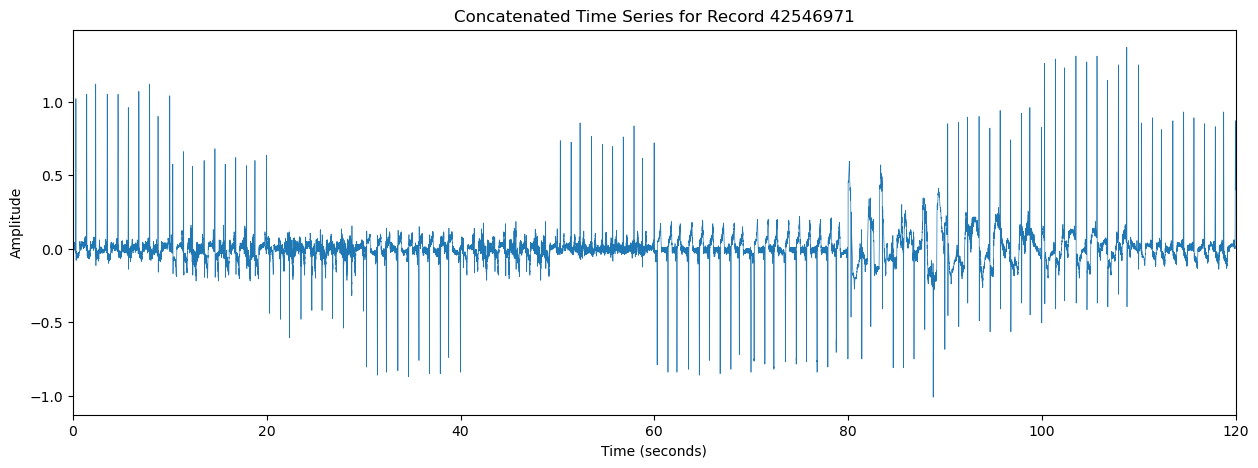

In [150]:

#Plot the first complete concatenated time series
first_record = list(timeseries_dict.keys())[0]
ts_data = timeseries_dict[first_record]
time_axis = np.arange(ts_data['total_length']) / ts_data['fs']
plt.figure(figsize=(15, 5))
plt.plot(time_axis, ts_data['signal'], linewidth=0.5)
plt.title(f"Concatenated Time Series for Record {first_record}")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.xlim(0, ts_data['duration_seconds'] * ts_data['num_channels'])
plt.show()

# Time Series Understanding

Given a time series, it is interesting to understand the behaviour of the it; to do so we can check for some particular informations:
- **Trends**
- **Seasonality**
- **Cyclicity**

## Noise removal

### Rolling window approach

The first idea to remove noise in the time series is to use a rolling window (with a defeault value of 5), and smooth the curve. 

In [151]:
# Remove noise in the time series by applying a rolling window average filter
def moving_average(signal, window_size=5):
    """
    Apply moving average filter to a numpy array signal.
    
    Parameters:
    -----------
    signal : numpy.ndarray
        Input signal
    window_size : int
        Size of the moving average window
        
    Returns:
    --------
    pandas.Series
        Filtered signal with NaN at edges
    """
    # Convert to pandas Series for rolling window operations
    signal_series = pd.Series(signal)
    
    # Standardize: (x - mean) / std
    standardized = (signal_series - signal_series.mean()) / signal_series.std()
    
    # Apply rolling window average
    filtered = standardized.rolling(window=window_size, center=True).mean()
    
    return filtered


### Low/High-Pass and Band-Pass filters

Another option is to use *Low-Pass*, *High-Pass* and *Band-Pass* filters to remove the noise on ECG signals.
- **Low-Pass filter**: A Low-Pass filter (LPF) is a filter that passes signals with a frequency lower than a selected cutoff frequency and attenuates signals with frequencies higher than the cutoff frequency.
- **High-Pass filter**: A High-Pass filter (HPF) is an electronic filter that passes signals with a frequency higher than a certain cutoff frequency and attenuates signals with frequencies lower than the cutoff frequency.
- **Band-Pass filter**: A Band-Pass filter allows through components in a specified band of frequencies, called its passband but blocks components with frequencies above or below this band. This contrasts with a high-pass filter, which allows through components with frequencies above a specific frequency, and a low-pass filter, which allows through components with frequencies below a specific frequency.

In [152]:
def low_pass_filter(signal, fs, cutoff=30, order=5):
    """
    Apply a low-pass Butterworth filter to the signal.

    Parameters:
    signal : numpy.ndarray
        Input signal
    fs : float
        Sampling frequency
    cutoff : float
        Cutoff frequency of the filter
    order : int
        Order of the filter
    Returns:
    numpy.ndarray
        Filtered signal
    """
    # Calculate the Nyquist frequency
    nyquist = 0.5 * fs

    # Normalized cutoff frequency
    normal_cutoff = cutoff / nyquist

    # Get the filter coefficients
    b, a = butter(order, normal_cutoff, btype='low', analog=False)

    # Apply the filter
    filtered_signal = filtfilt(b, a, signal)
    return filtered_signal

def high_pass_filter(signal, fs, cutoff=0.5, order=5):
    """
    Apply a high-pass Butterworth filter to the signal.

    Parameters:
    signal : numpy.ndarray
        Input signal
    fs : float
        Sampling frequency
    cutoff : float
        Cutoff frequency of the filter
    order : int
        Order of the filter
    Returns:
    numpy.ndarray
        Filtered signal
    """
    # Calculate the Nyquist frequency
    nyquist = 0.5 * fs

    # Normalized cutoff frequency
    normal_cutoff = cutoff / nyquist

    # Get the filter coefficients
    b, a = butter(order, normal_cutoff, btype='high', analog=False)

    # Apply the filter
    filtered_signal = filtfilt(b, a, signal)
    return filtered_signal

def band_pass_filter(signal, fs, lowcut=0.5, highcut=30, order=5):
    """
    Apply a band-pass Butterworth filter to the signal.

    Parameters:
    signal : numpy.ndarray
        Input signal
    fs : float
        Sampling frequency
    lowcut : float
        Low cutoff frequency of the filter
    highcut : float
        High cutoff frequency of the filter
    order : int
        Order of the filter
    Returns:
    numpy.ndarray
        Filtered signal
    """
    # Calculate the Nyquist frequency
    nyquist = 0.5 * fs

    # Normalized cutoff frequencies
    low = lowcut / nyquist
    high = highcut / nyquist

    # Get the filter coefficients
    b, a = butter(order, [low, high], btype='band')

    # Apply the filter
    filtered_signal = filtfilt(b, a, signal)
    return filtered_signal


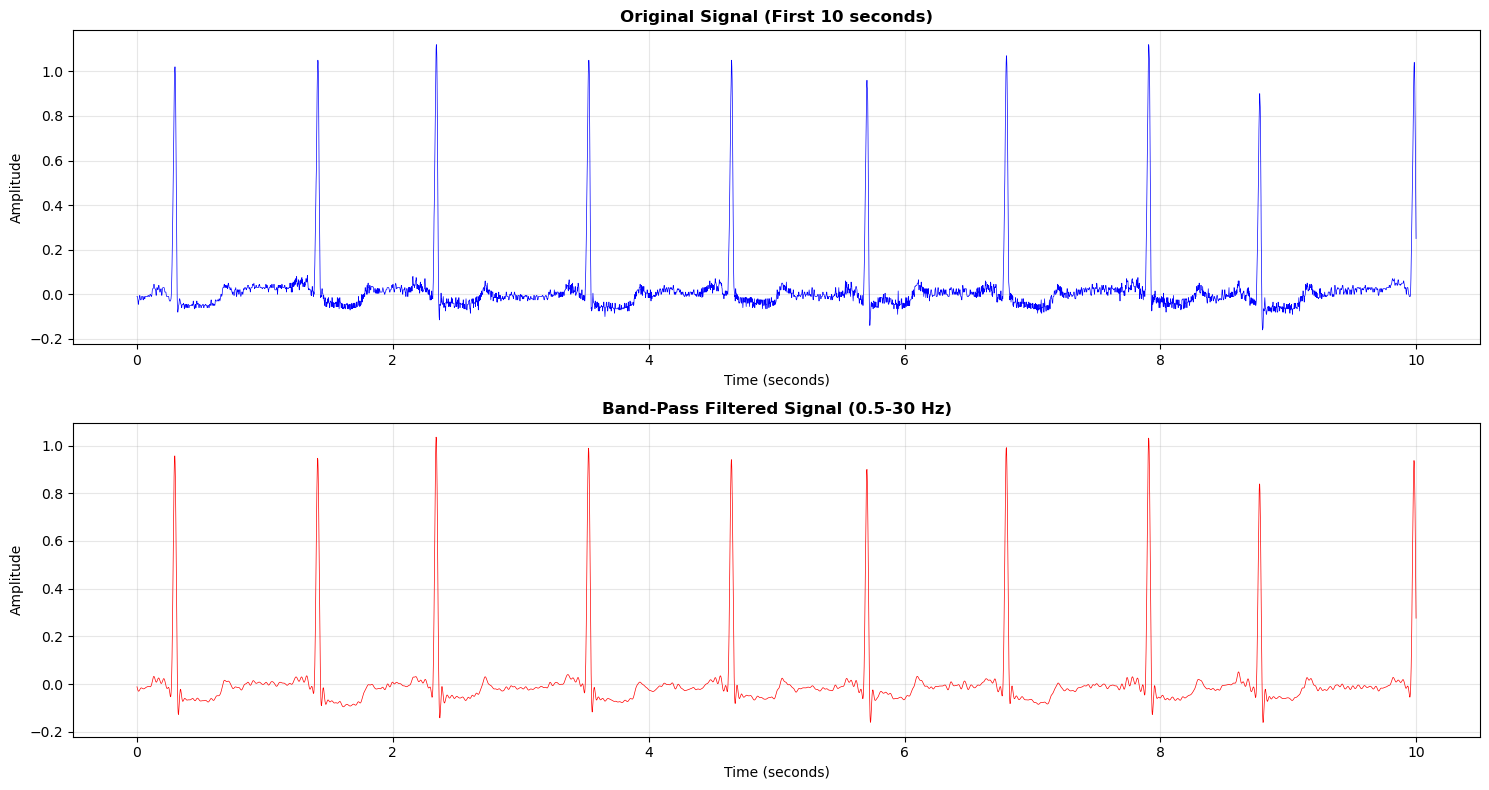

In [153]:
filtered_signal_bp = band_pass_filter(ts_data['signal'], fs=ts_data['fs'], lowcut=0.5, highcut=30, order=5)

# Plot comparison for first 10 seconds
fs = ts_data['fs']
samples_10s = int(10 * fs)
time_10s = np.arange(samples_10s) / fs

plt.figure(figsize=(15, 8), dpi=100)

# Original signal
plt.subplot(2, 1, 1)
plt.plot(time_10s, ts_data['signal'][:samples_10s], linewidth=0.5, color='blue')
plt.title('Original Signal (First 10 seconds)', fontweight='bold')
plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude')
plt.grid(True, alpha=0.3)

# Filtered signal
plt.subplot(2, 1, 2)
plt.plot(time_10s, filtered_signal_bp[:samples_10s], linewidth=0.5, color='red')
plt.title('Band-Pass Filtered Signal (0.5-30 Hz)', fontweight='bold')
plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Having cancelled the noise from the signal, we can now check for seasonality using the auto-correlation method.

In [154]:
from statsmodels.tsa.stattools import acf
from scipy.signal import find_peaks

fs = ts_data['fs']  # e.g., 125 Hz

# Cover 3-5 complete heartbeat cycles
# For heart rate range 40-120 bpm (0.67-2 Hz)
max_cycles = 5
min_heart_rate_hz = 0.67  # 40 bpm
MAX_LAGS = int(max_cycles * fs / min_heart_rate_hz)

print(f"MAX_LAGS: {MAX_LAGS} samples ({MAX_LAGS/fs:.1f} seconds)")

# Compute and plot ACF for the filtered signal
lag_acf = acf(filtered_signal_bp, fft=True, nlags=MAX_LAGS)

MAX_LAGS: 3731 samples (7.5 seconds)


In [155]:
# Find peaks in the ACF
peaks, _ = find_peaks(lag_acf, height=0)

if len(peaks) > 1:
    # First peak is at lag 0, second peak gives the fundamental period
    fundamental_lag = peaks[1]
    fundamental_period_seconds = fundamental_lag / fs
    estimated_heart_rate_bpm = 60 / fundamental_period_seconds

    print(f"Estimated Heart Rate: {estimated_heart_rate_bpm:.2f} bpm (Fundamental Period: {fundamental_period_seconds:.2f} seconds)")
else:
    print("Not enough peaks found in the ACF to estimate heart rate.")

Estimated Heart Rate: 69.12 bpm (Fundamental Period: 0.87 seconds)


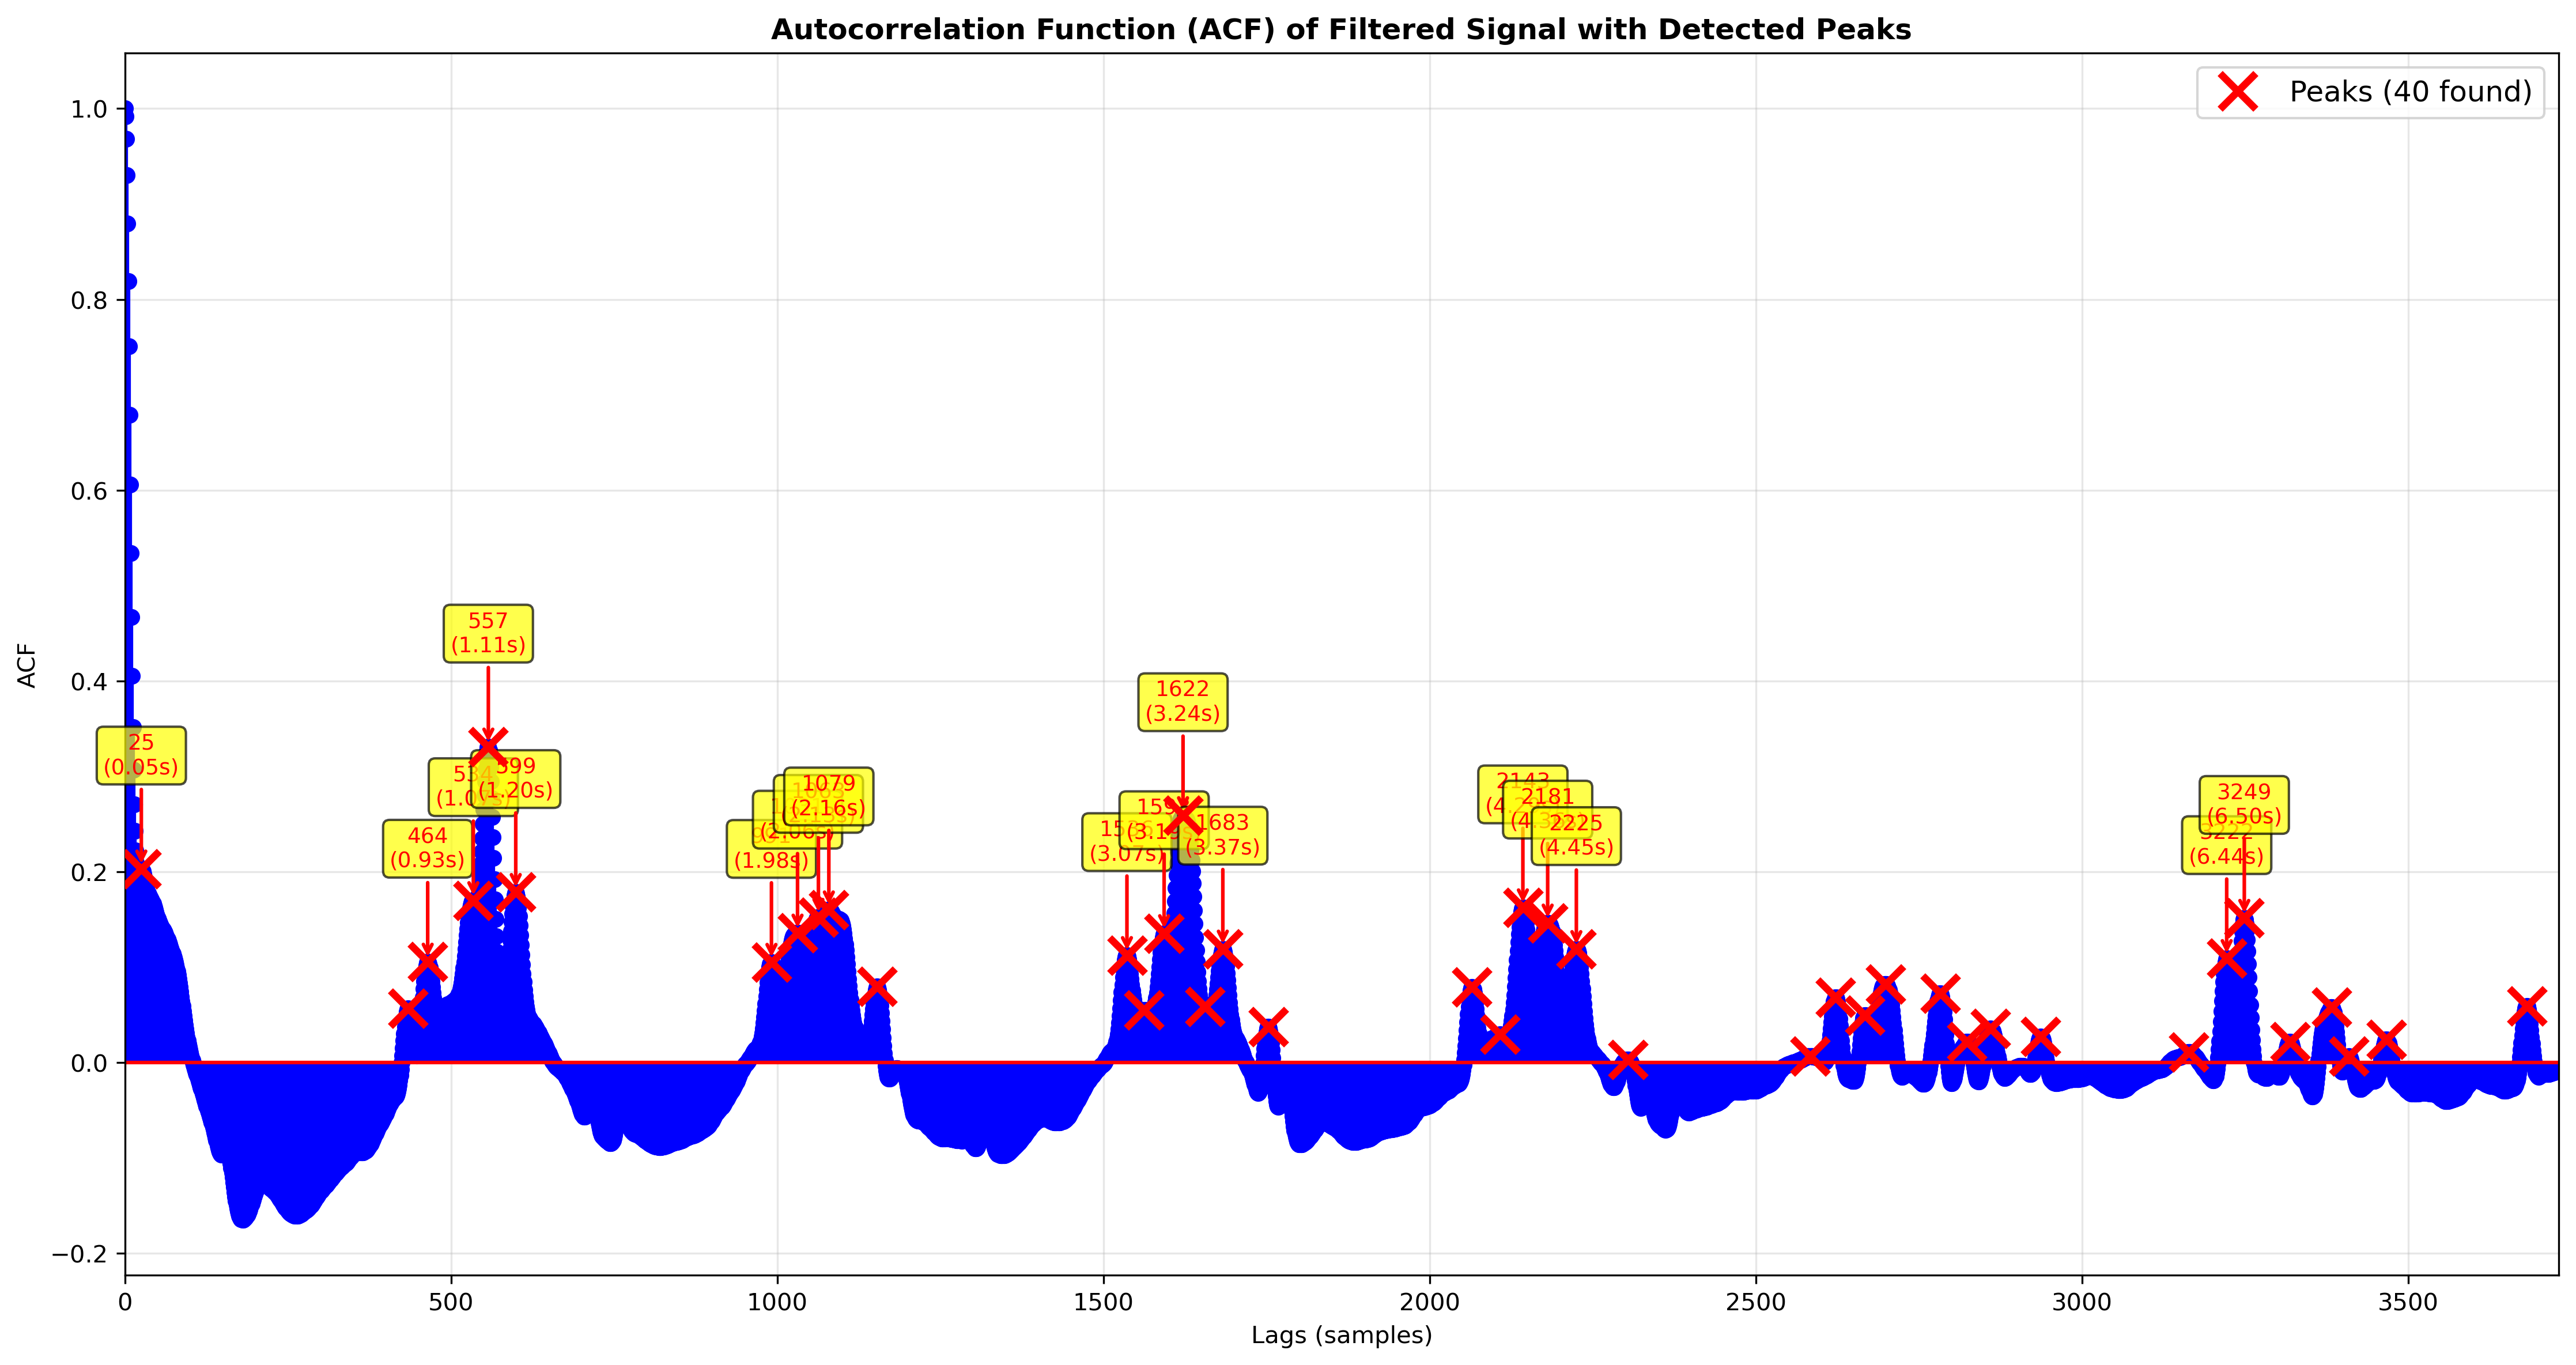


Detected Peaks in ACF
Peak #   Lag        Time (s)     Heart Rate      ACF Value 
----------------------------------------------------------------------
1        25         0.050        1200.0          0.2032    
2        434        0.868        69.1            0.0568    
3        464        0.928        64.7            0.1056    
4        534        1.068        56.2            0.1701    
5        557        1.114        53.9            0.3311    
6        599        1.198        50.1            0.1786    
7        991        1.982        30.3            0.1054    
8        1031       2.062        29.1            0.1360    
9        1063       2.126        28.2            0.1526    
10       1079       2.158        27.8            0.1604    
11       1153       2.306        26.0            0.0796    
12       1536       3.072        19.5            0.1125    
13       1562       3.124        19.2            0.0550    
14       1593       3.186        18.8            0.1355    
15    

In [156]:
plt.figure(figsize=(15, 8), dpi=300)

# Plot stem first (in background)
plt.stem(range(len(lag_acf)), lag_acf, linefmt='b-', markerfmt='bo', basefmt='r-')

# Plot peaks on top with larger, more visible markers
if len(peaks) > 0:
    plt.plot(peaks, lag_acf[peaks], "x", markersize=15, markeredgewidth=3, 
             label=f"Peaks ({len(peaks)} found)", color='red', zorder=5)
    
    # Annotate the first few significant peaks
    for i, peak in enumerate(peaks):
        if lag_acf[peak] > 0.1:  # Only annotate significant peaks
            plt.annotate(f'{peak}\n({peak/fs:.2f}s)', 
                        xy=(peak, lag_acf[peak]), 
                        xytext=(peak, lag_acf[peak] + 0.1),
                        ha='center',
                        fontsize=9,
                        color='red',
                        bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.7),
                        arrowprops=dict(arrowstyle='->', color='red', lw=1.5))

plt.title('Autocorrelation Function (ACF) of Filtered Signal with Detected Peaks', fontweight='bold')
plt.xlabel('Lags (samples)')
plt.ylabel('ACF')
plt.grid(True, alpha=0.3)
plt.xlim(0, MAX_LAGS)
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()

# Print peak information
if len(peaks) > 0:
    print(f"\n{'='*70}")
    print(f"Detected Peaks in ACF")
    print(f"{'='*70}")
    print(f"{'Peak #':<8} {'Lag':<10} {'Time (s)':<12} {'Heart Rate':<15} {'ACF Value':<10}")
    print(f"{'-'*70}")
    for i, peak in enumerate(peaks, 1): 
        time_s = peak / fs
        bpm = 60 * fs / peak if peak > 0 else 0
        print(f"{i:<8} {peak:<10} {time_s:<12.3f} {bpm:<15.1f} {lag_acf[peak]:<10.4f}")
    print(f"{'='*70}\n")
else:
    print("No peaks detected in ACF")

### Triple Exponential Smoothing (Holt-Winters method)

In [157]:
def hw_method(series, seasonal_periods, trend='add', seasonal='add'):
    """
    Apply Holt-Winters Exponential Smoothing to a time series.
    
    Parameters:
    -----------
    series : array-like
        Input time series data
    seasonal_periods : int
        Number of periods in a complete seasonal cycle
    trend : str
        Type of trend component ('add' or 'mul')
    seasonal : str
        Type of seasonal component ('add' or 'mul')
    
    Returns:
    --------
    fitted_model : ExponentialSmoothing results object
        Fitted Holt-Winters model
    """
    model = ExponentialSmoothing(
        series,
        trend=trend,
        seasonal=seasonal,
        seasonal_periods=seasonal_periods
    )
    fit_model = model.fit()
    return fit_model


def plot_hw_decomposition(series, fitted):
    # Extract Holt-Winters internal components
    level = fitted.level
    trend = fitted.trend
    seasonal = fitted.season
    fittedvalues = fitted.fittedvalues
    
    # Remainder (error)
    remainder = series - fittedvalues

    # ----- Plot -----
    fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True, dpi = 300)
    
    # 1. Original time series
    axes[0].plot(series, color="black")
    axes[0].set_title("Time series (data)")
    
    # 2. Seasonal component
    axes[1].plot(seasonal, color="teal")
    axes[1].set_title("Seasonal patterns")
    
    # 3. Trend component
    axes[2].plot(trend, color="red")
    axes[2].set_title("General tendencies (trend)")
    
    # 4. Remainder
    axes[3].plot(remainder, color="green")
    axes[3].set_title("Error / Remainder")

    plt.xlabel("Time")
    plt.tight_layout()
    plt.show()

/Users/tommy/miniconda3/envs/DA4DH/lib/python3.13/site-packages/statsmodels/tsa/holtwinters/model.py:903: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(


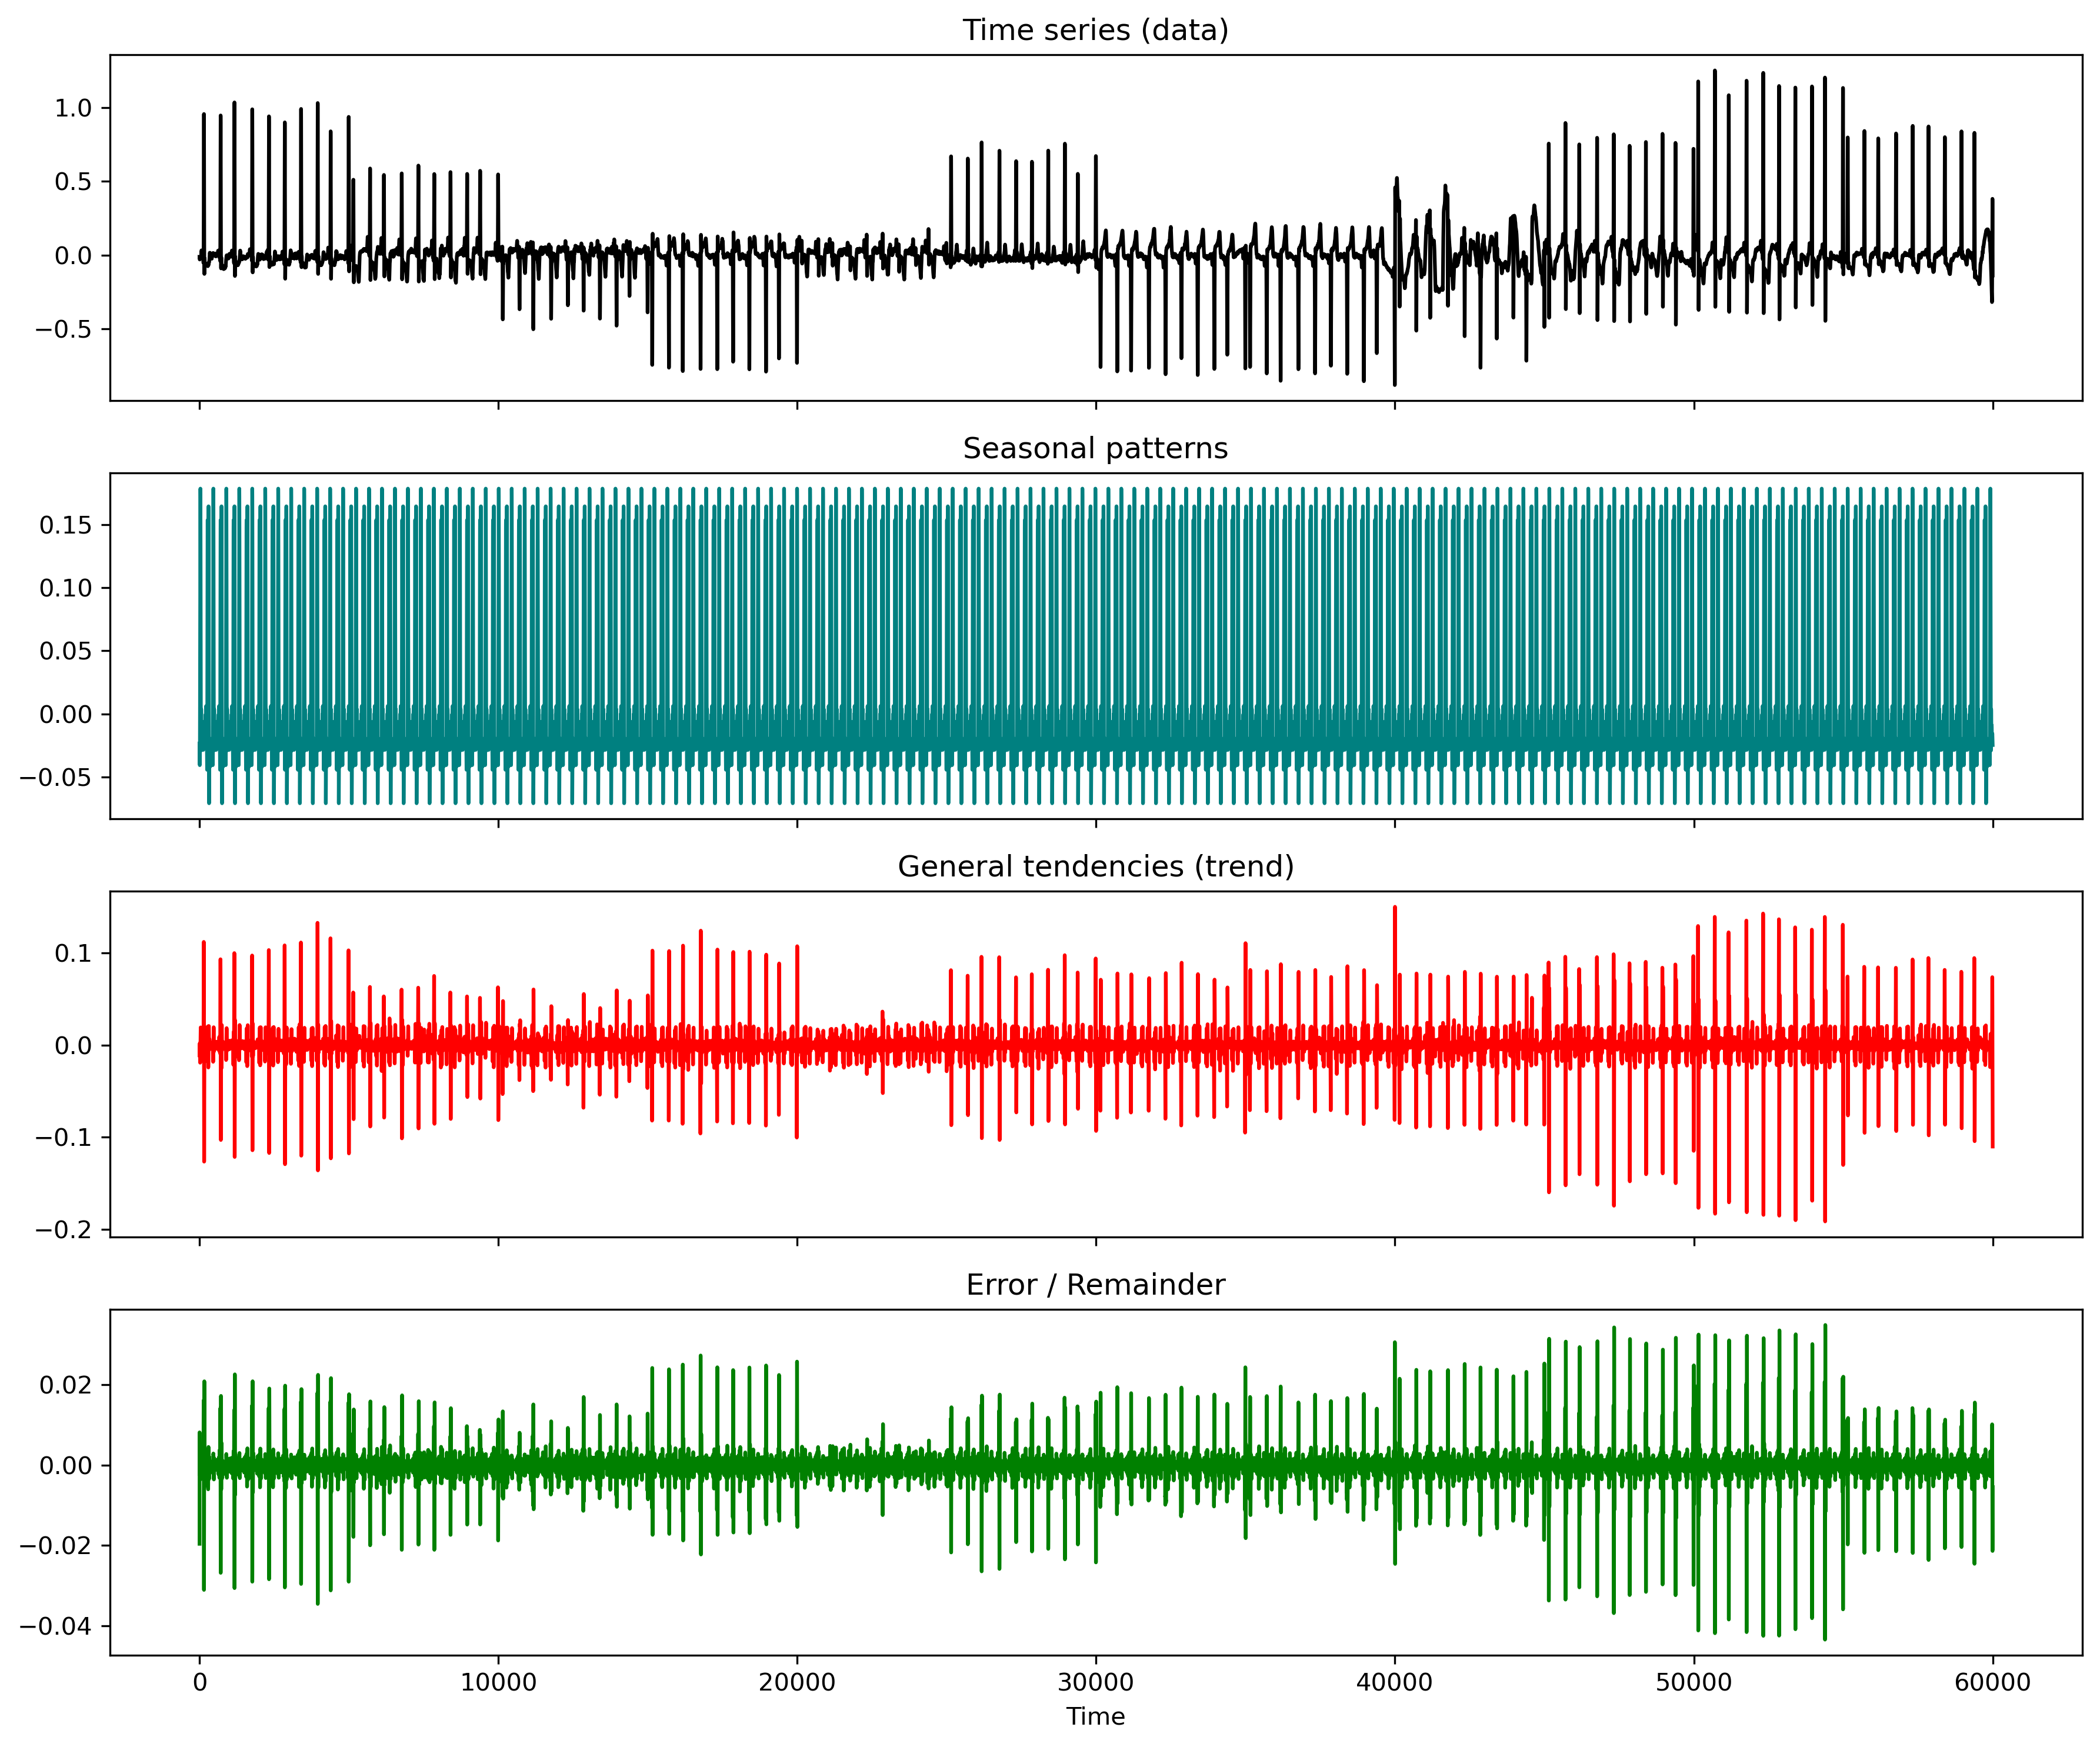

In [158]:
# Optimal seasonal periods based on ACF peaks
optimal_seasonal_periods = peaks[1]

fitted_model = hw_method(filtered_signal_bp, seasonal_periods=optimal_seasonal_periods, trend='add', seasonal='add')
plot_hw_decomposition(filtered_signal_bp, fitted_model)


Due to the highly irregular behaviour of the ECGs, Holter-Winters method can fail to get seasonality. In the specific case of ECGs, we can apply the Pan-Tompkins algorithm.

### Pan-Tompkins algorithm

In [159]:
def pt_algorithm(signal, fs):
    """
    Apply the Pan-Tompkins algorithm to detect R-peaks in ECG signals.
    
    Parameters:
    -----------
    signal : numpy.ndarray
        Input ECG signal
    fs : float
        Sampling frequency
        
    Returns:
    --------
    r_peaks : numpy.ndarray
        Indices of detected R-peaks in the signal
    """
    # Step 1: Band-pass filter (0.5-30 Hz)
    filtered_signal = band_pass_filter(signal, fs, lowcut=0.5, highcut=30, order=5)
    
    # Step 2: Derivative filter
    derivative_signal = np.diff(filtered_signal)
    
    # Step 3: Squaring
    squared_signal = np.square(derivative_signal)
    
    # Step 4: Moving window integration
    window_size = int(0.150 * fs)  # 150 ms window
    integrated_signal = moving_average(squared_signal, window_size=window_size).fillna(0).values
    
    return integrated_signal

In [160]:
def QRSpeaks(signal, fs):
    """
    Detect QRS peaks (R-peaks) in Pan-Tompkins processed signal.
    
    Parameters:
    -----------
    signal : numpy.ndarray
        Integrated signal from Pan-Tompkins algorithm
    fs : float
        Sampling frequency
        
    Returns:
    --------
    peaks : numpy.ndarray
        Indices of detected R-peaks
    """
    # Use find_peaks from scipy.signal (already imported)
    peaks, _ = find_peaks(signal, height=np.mean(signal), distance=round(fs*0.200))
    return peaks

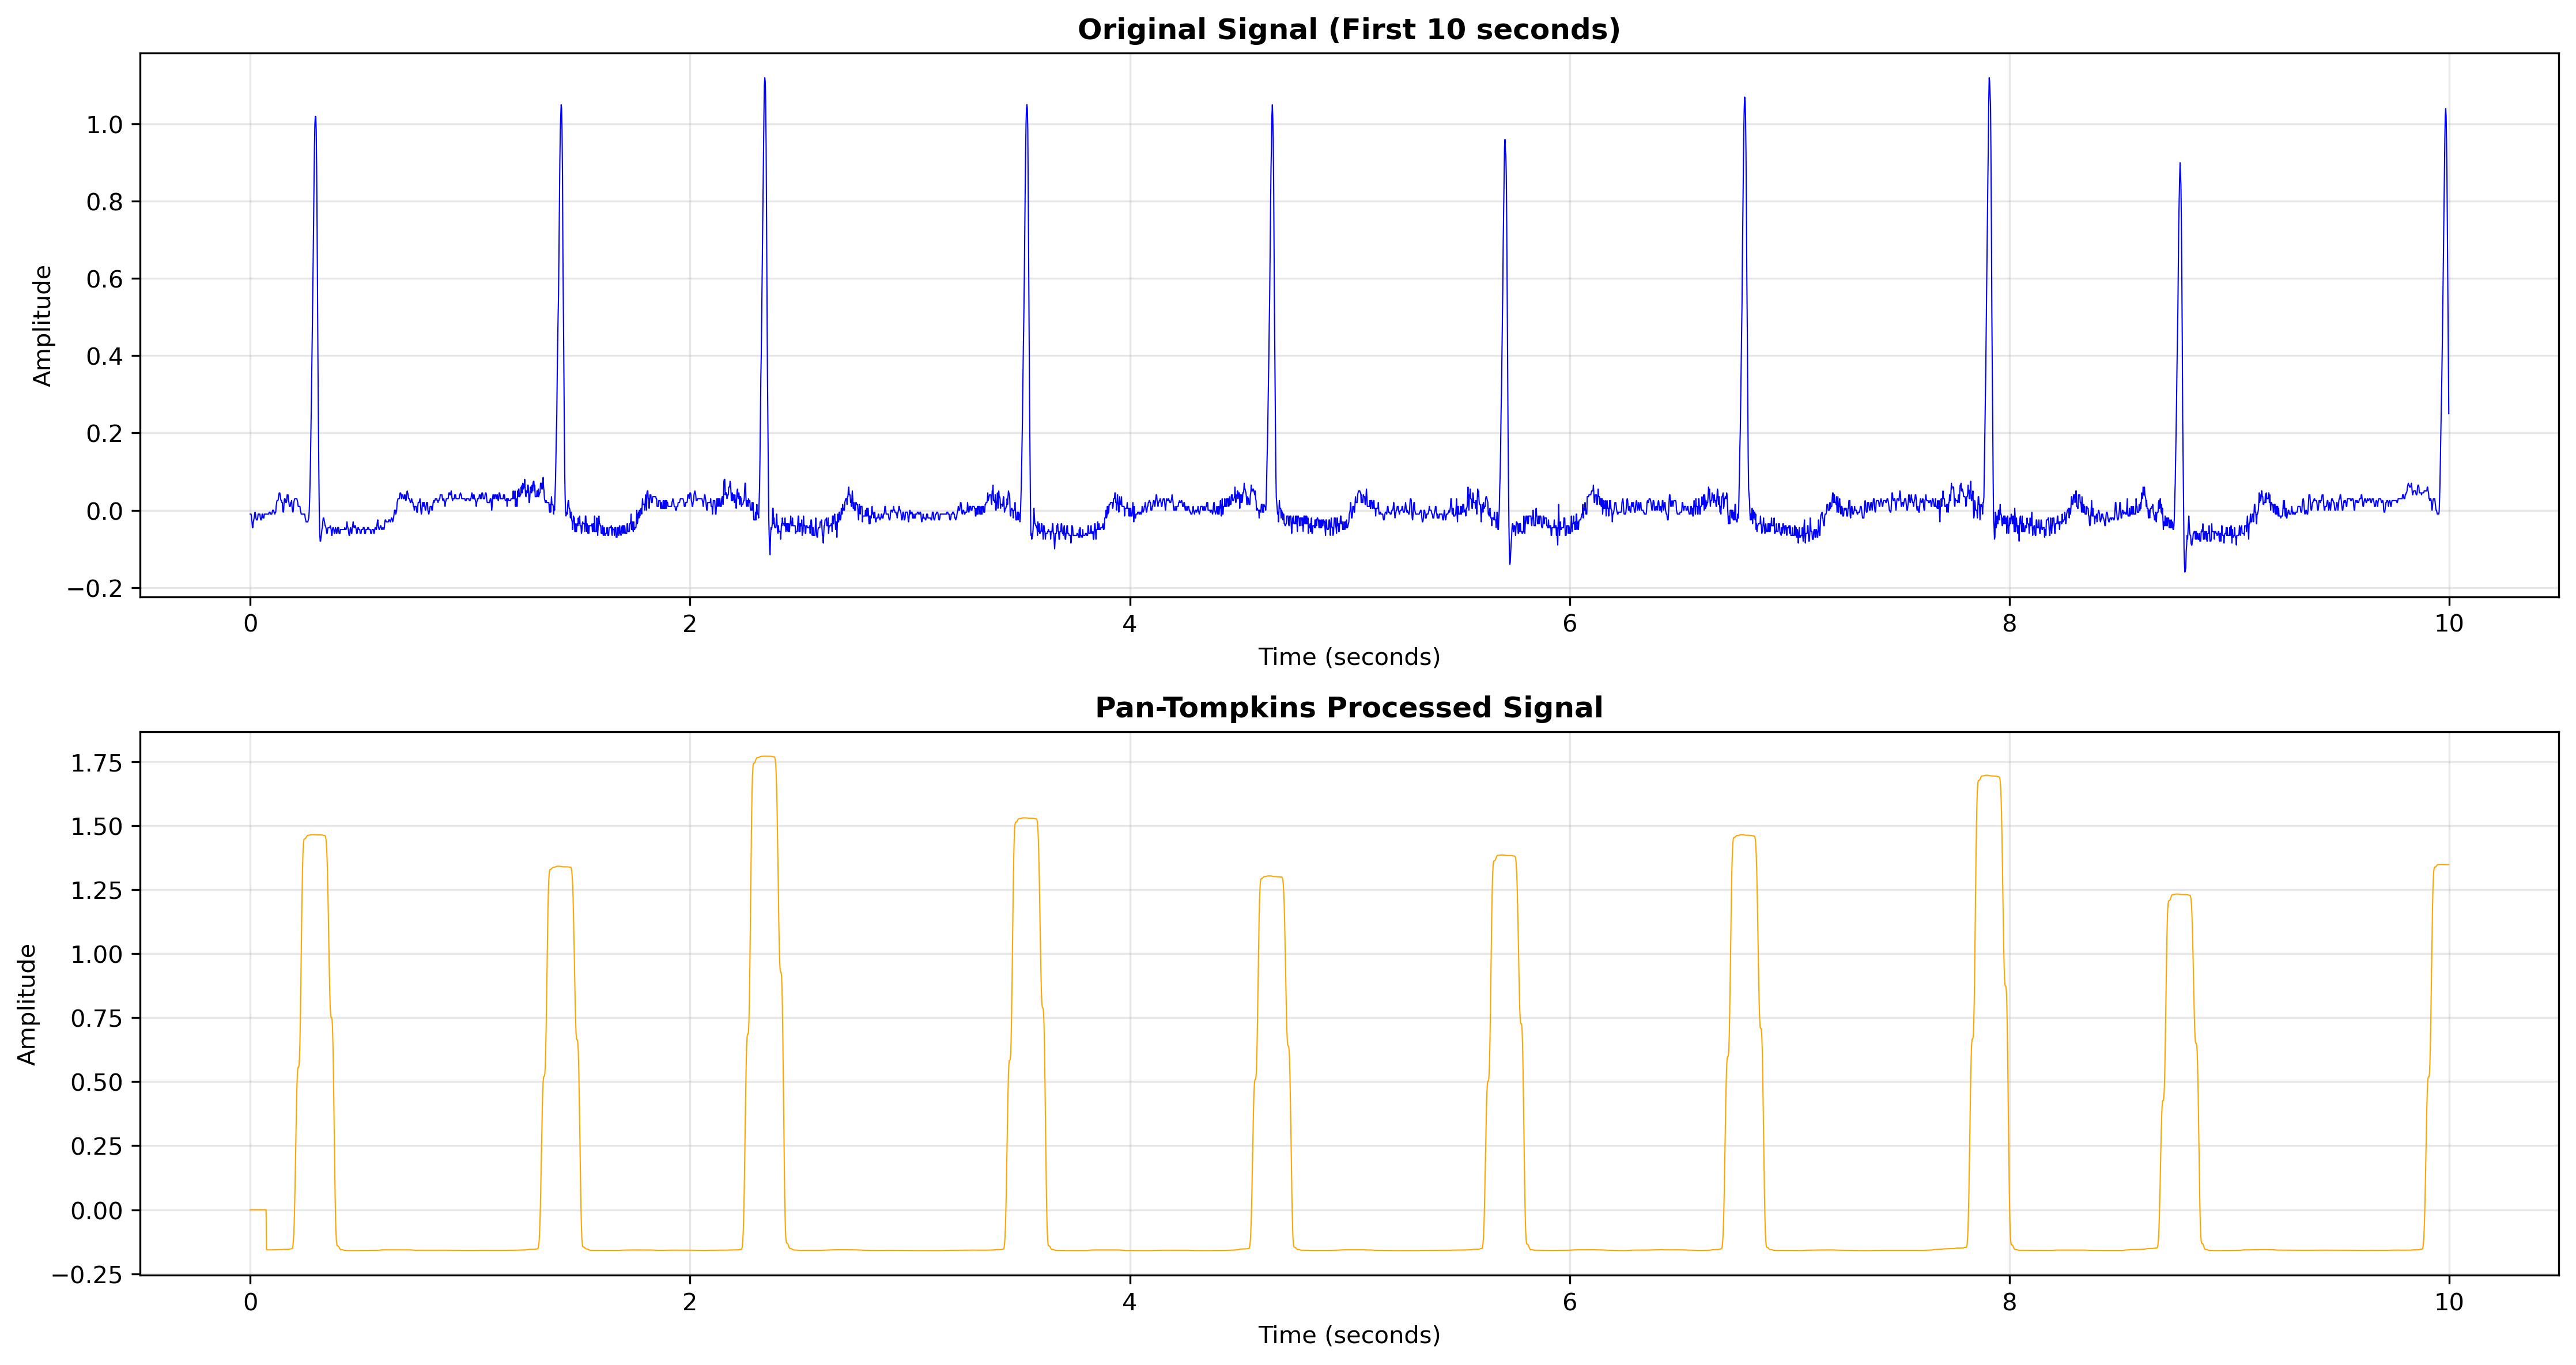

In [161]:
pt_filtered_signal = pt_algorithm(ts_data['signal'], fs=ts_data['fs'])

# Plot the Pan-Tompkins processed signal over the original signal for first 10 seconds
fs = ts_data['fs']
samples_10s = int(10 * fs)
time_10s = np.arange(samples_10s) / fs
plt.figure(figsize=(15, 8), dpi=300)
# Original signal
plt.subplot(2, 1, 1)
plt.plot(time_10s, ts_data['signal'][:samples_10s], linewidth=0.5, color='blue')
plt.title('Original Signal (First 10 seconds)', fontweight='bold')
plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude')
plt.grid(True, alpha=0.3)
# Pan-Tompkins processed signal
plt.subplot(2, 1, 2)
plt.plot(time_10s, pt_filtered_signal[:samples_10s], linewidth=0.5, color='orange')
plt.title('Pan-Tompkins Processed Signal', fontweight='bold')
plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Detected 110 R-peaks in the ECG signal.


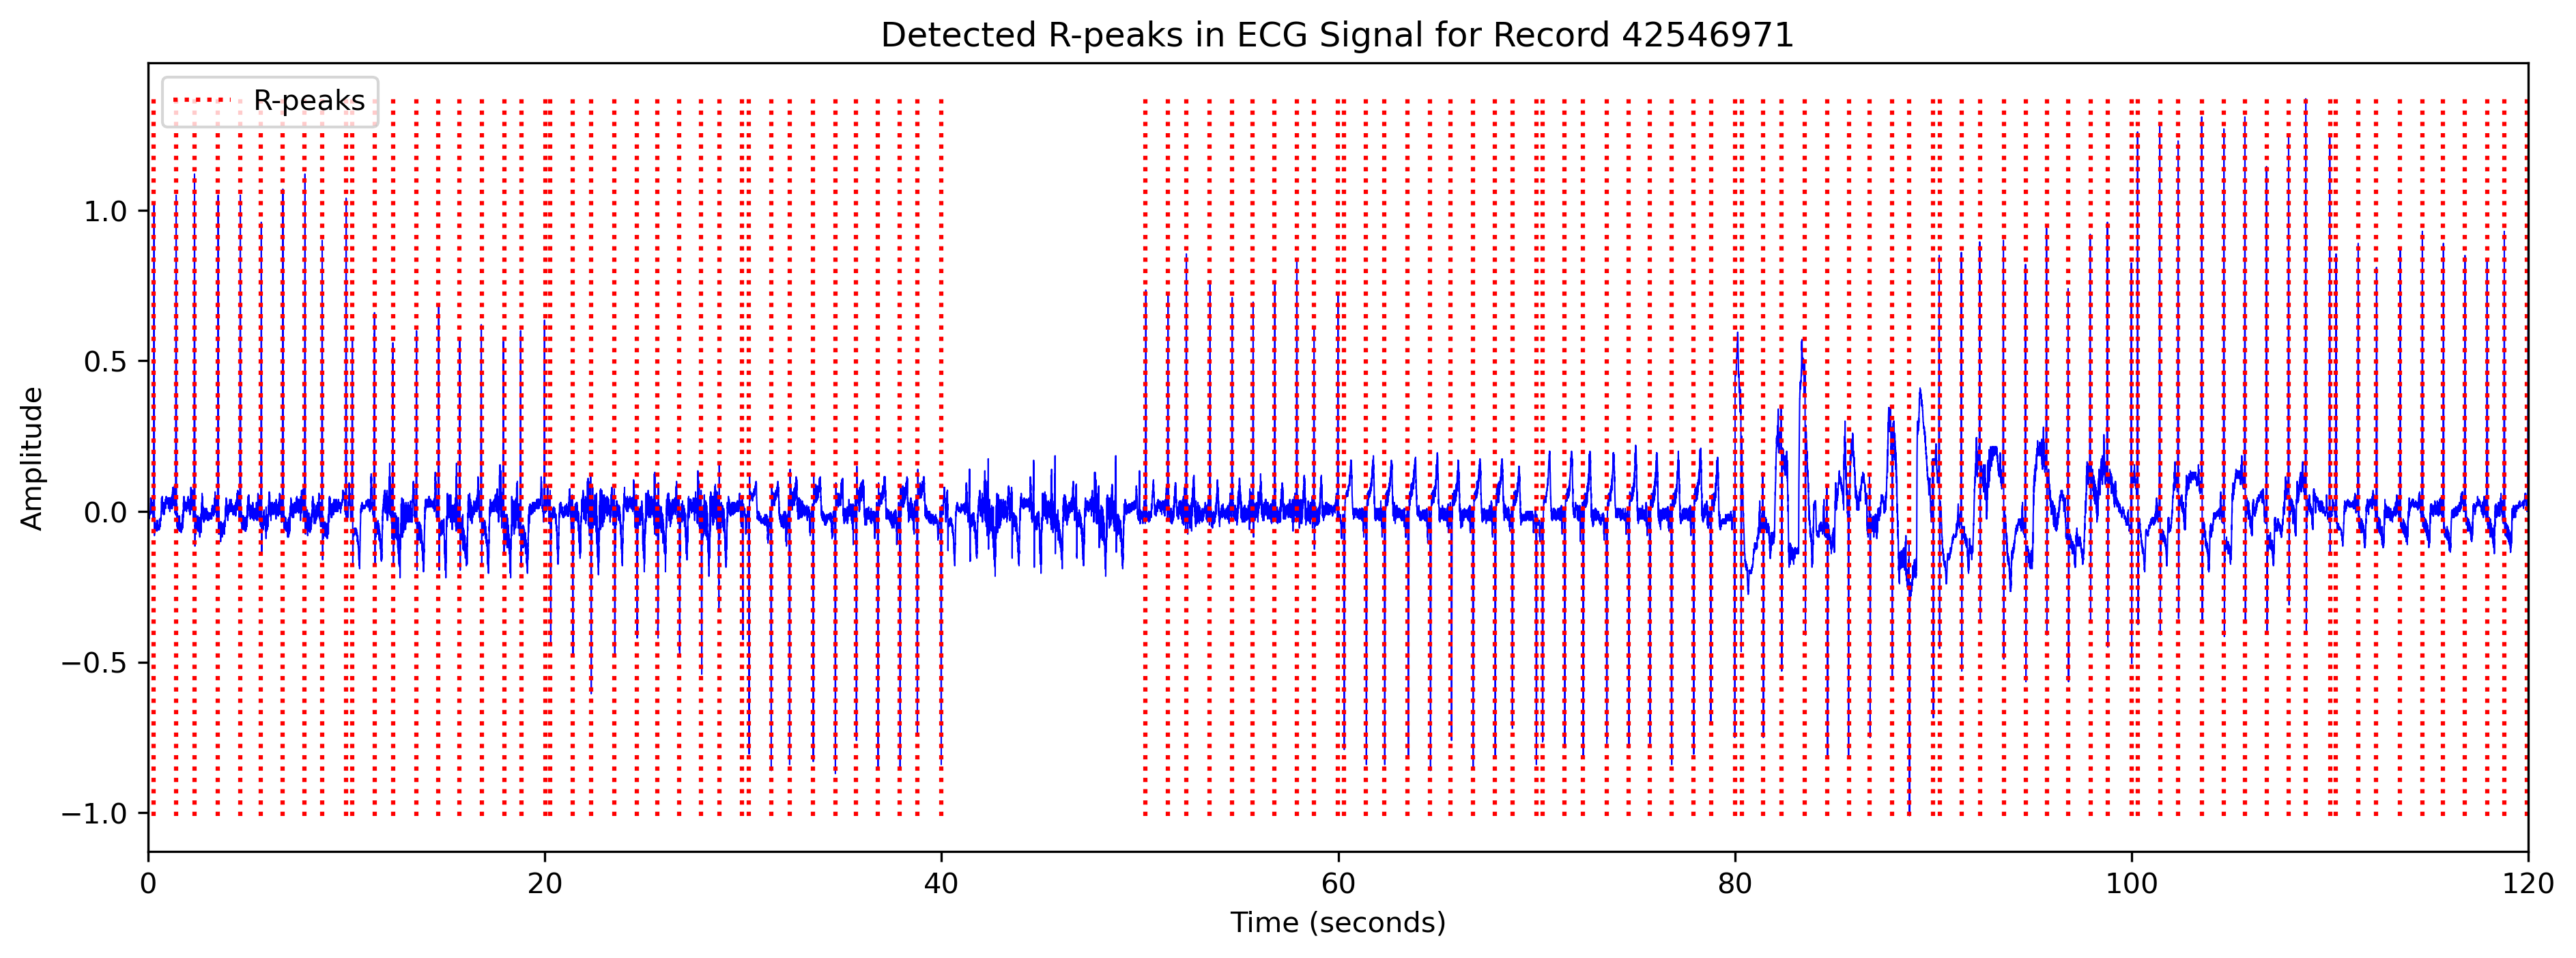

In [162]:
r_peaks = QRSpeaks(pt_filtered_signal, fs=ts_data['fs'])
print(f"Detected {len(r_peaks)} R-peaks in the ECG signal.")

# Plot detected R-peaks (vertical dotted lines) on original signal for the full duration
time_axis = np.arange(ts_data['total_length']) / ts_data['fs']
plt.figure(figsize=(15, 5), dpi=300)
plt.plot(time_axis, ts_data['signal'], linewidth=0.5, color='blue')
plt.vlines(r_peaks / ts_data['fs'], ymin=min(ts_data['signal']), ymax=max(ts_data['signal']), colors='red', linestyles='dotted', label='R-peaks')
plt.title(f"Detected R-peaks in ECG Signal for Record {first_record}")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.xlim(0, ts_data['duration_seconds'] * ts_data['num_channels'])
plt.legend()
plt.show()
